# Introduction

This notebook contains the entire `TrenchRipper` pipline, divided into simple steps. This pipline is ideal for Mother <br>Machine image data where cells possess fluorescent segmentation markers. Segmentation on phase or brightfield data <br>is being developed, but is still an experimental feature.

The steps in this pipeline are as follows:
1. Extracting your Mother Machine data (.nd2) into hdf5 format
2. Identifying and cropping individual trenches into kymographs
3. Segmenting cells with a fluorescent marker
4. Determining lineages and object properties

In each step, the user will dynamically specify parameters using a series of interactive diagnostics on their dataset. <br>Following this, a parameter file will be written to disk and then used to deploy a parallel computation on the <br>dataset, either locally or on a SLURM cluster.


This is intended as an end-to-end solution to analyzing Mother Machine data. As such, **it is not trivial to plug data <br>directly into intermediate steps**, as it will lack the correct formatting and associated metadata. A notable <br>exception to this is using another program to segment data. The library references binary segmentation masks using <br>only metadata derived from their associated kymographs. As such, it is possible to generate segmentations on these <br>kymographs elsewhere and place them into the segmentation data path to have `TrenchRipper` act on those <br>segmentations instead. More on this in the segmentation section...

#### Imports

Run this section to import all relavent packages and libraries used in this notebook. You must run this everytime you open a new python kernel.

In [ ]:
# Notebook initially copied from: 2023-10-31_lLAG2_AF555-AllCycles

In [1]:
print(1)

1


In [2]:
import warnings

import paulssonlab.deaton.trenchripper.trenchripper as tr

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [3]:
# addition of active memory manager
import dask

dask.config.set({"distributed.scheduler.active-memory-manager.start": True})
dask.config.set({"distributed.scheduler.worker-ttl": "5m"})
dask.config.set({"distributed.scheduler.allowed-failures": 100})

dask_wd = "/home/lag36/scratch/lag36/dask/"

# Part 0: Flat Field Generation

### Dark Image

flatfieldpath = "/home/de64/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/DarkImage_40x_Phase.nd2"
outputpath = "/home/de64/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/40x_DarkImage.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### Cy5-Penta

flatfieldpath = "/home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy5-Penta_20x_Phase.nd2"
outputpath = "/home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy5-Penta_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### Cy7-Penta

flatfieldpath = "/home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy7-Penta_20x_Phase.nd2"
outputpath = "/home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy7-Penta_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### GFP-Penta

flatfieldpath = "/home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Phase.nd2"
outputpath = "/home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

### MCherry

flatfieldpath = "/home/de64/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_20x/mCherry_20x_Phase.nd2"
outputpath = "/home/de64/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_20x/mCherry_20x_Ph2_flatfield.tiff"
tr.generate_flatfield(flatfieldpath,outputpath)

In [ ]:
# Luis: Modified to the already-extracted 40X Flat Fields

# \\research.files.med.harvard.edu\SysBio\PAULSSON LAB\Personal_Folders\Daniel\Image_Data\Flat_Fields\Ti5

In [ ]:
tr.generate_flatfield('/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.nd2',
                      '/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff')

In [ ]:
headpath = '/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/'

# List .nd2 files in headpath
import os

nd2_files = [f for f in os.listdir(headpath) if f.endswith('.nd2')]

channels = [nd2_files.split('.')[0] for nd2_files in nd2_files]
channels = ['20X_Cy5-Penta', '20X_Dark', '20X_MicroManager-Phase', '20X_RFP-Penta', '20X_mCherry']

for channel in channels:
    tr.generate_flatfield(headpath + channel + '.nd2', headpath + channel + '.tiff')

In [ ]:
import tifffile
from matplotlib import pyplot as plt

dark_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff"
)

Cy5_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff"
)

RFP_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff"
)

Mcherry_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_mCherry.tiff"
)

BF_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff"
)

fflist = [
    dark_outputpath,
    BF_outputpath,
    Cy5_outputpath,
    # Cy7_outputpath,
    # GFP_outputpath,
    RFP_outputpath,
    Mcherry_outputpath,
]

fig, axs = plt.subplots(figsize=(15, 20), nrows=1, ncols=len(fflist))

for i in range(len(fflist)):
    print(fflist[i])
    axs[i].imshow(tifffile.imread(fflist[i]))
    axs[i].set_title(fflist[i].split('/')[-1].split('_')[1]) #
    # axs[i].set_title(fflist[i].split("/")[-1].split("_")[1])  # CHANGED BY LUIS
plt.tight_layout()


# Part 1: Growth/Division

#### Specify Paths

Begin by defining the directory in which all processing will be done, as well as the initial nd2 file we will be <br>processing. This line should be run everytime you open a new python kernel.

The format should be: `headpath = "/path/to/folder"` and `nd2file = "/path/to/file.nd2"`

For example:
```
headpath = "/n/scratch2/de64/2019-05-31_validation_data"
nd2file = "/n/scratch2/de64/2019-05-31_validation_data/Main_Experiment.nd2"
```

Ideally, these files should be placed in a storage location with relatively fast I/O

In [3]:
headpath = "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/"
nd2file = "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Experiment.nd2"

## Extract to hdf5 files

In this section, we will be extracting our image data. Currently this notebook only supports `.nd2` format; however <br>there are `.tiff` extractors in the TrenchRipper source files that are being added to `Master.ipynb` soon.

In the abstract, this step will take a single `.nd2` file and split it into a set of `.hdf5` files stored in <br>`headpath/hdf5`. Splitting the file up in this way will facilitate quick procesing in later steps. Each field of <br>view will be split into one or more `.hdf5` files, depending on the number of images per file requested (more on <br>this later). 

To keep track of which output files correspond to which FOVs, as well as to keep track of experiment metadata, the <br>extractor also outputs a `metadata.hdf5` file in the `headpath` folder. The data from this step is accessible in <br>that `metadata.hdf5` file under the `global` key. If you would like to look at this metadata, you may use the <br>`tr.utils.pandas_hdf5_handler` to read from this file. Later steps will add additional metadata under different <br>keys into the `metadata.hdf5` file.

#### Start Dask Workers

First, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [ ]:
# dask_controller = tr.trcluster.dask_controller(
#     walltime="1:00:00",
#     local=False,
#     n_workers=100,
#     n_workers_min=20,
#     memory="8GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

In [ ]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=200,#500,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

After running the above line, you will have a running Dask client. Run the line below and click the link to supervise <br>the computation being administered by the scheduler. 

Don't be alarmed if the screen starts mostly blank, it may take time for your workers to spin up. If you get a 404 <br>error on a cluster, it is likely that your ports are not being forwarded properly. If this occurs, please register <br>the issue on github.

##### Perform Extraction

Now that we have our cluster scheduler spun up, it is time to convert files. This will be handled by the <br>`hdf5_extractor` object. This extractor will pull up each FOV and split it such that each derived `.hdf5` file <br>contains, at maximum, N timepoints of that FOV per file. The image data stored in these files takes the <br>form of `(N,Y,X)` arrays that are accessible using the desired channel name as a key. 

The arguments for this extractor are:

 - **nd2file** : The filepath to the `.nd2` file you intend to extract.
 
 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **tpts_per_file** : The maximum number of timepoints stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **ignore_fovmetadata** : Used when `.nd2` data is corrupted and does not possess records for stage positions or <br>timepoints. Only set `False` if the extractor throws errors on metadata handling.

 - **nd2reader_override** : Overrides values in metadata recovered using the `nd2reader`. Currently set to <br>`{"z_levels":[],"z_coordinates":[]}` by default to correct a known issue where z coordinates are mistakenly <br>interpreted as a z stack. See the [nd2reader](https://rbnvrw.github.io/nd2reader/) documentation for more info.

In [ ]:
hdf5_extractor = tr.ndextract.hdf5_fov_extractor(
    nd2file,
    headpath,
    tpts_per_file=50,
    ignore_fovmetadata=False,
    nd2reader_override={"z_levels": [], "z_coordinates": []},
)

##### Extraction Parameters

Here, you may set the time interval you want to extract. Useful for cropping data to the period exhibiting the dynamics of interest.

Optionally take notes to add to the `metadata.hdf5` file. Notes may also be taken directly in this notebook.

In [ ]:
hdf5_extractor.inter_set_params()

#### List of paths to flat fields
 - "/home/lag36/gutiloluis/FlatFields/2022-12-26_Ti5-40xPh2/40x_mCherry.tiff"
 - "/home/lag36/gutiloluis/FlatFields/2022-12-26_Ti5-40xPh2/40x_YFP.tiff"
 - "/home/lag36/gutiloluis/FlatFields/2022-12-26_Ti5-40xPh2/40x_DarkImage.tiff"

In [ ]:
# outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/40x_DarkImage.tiff"

# outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Ph2_flatfield.tiff"
# outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy7-Penta_20x_Ph2_flatfield.tiff"
# outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy5-Penta_20x_Ph2_flatfield.tiff"

# outputpath = "/home/cas77/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_20x/mCherry_20x_Ph2_flatfield.tiff"

In [ ]:
# Mcherry: /home/lag36/scratch/de64/sync_folder/2023-09-10_Flat_Fields_Iris_9_20x/mCherry_20x_Ph2_flatfield.tiff
# GFP: /home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Ph2_flatfield.tiff
# Dark: /home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-12-26_Flat_Fields_Iris_9_20x/40x_DarkImage.tiff

In [ ]:
dark_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff"
)

Cy5_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff"
)

RFP_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff"
)

Mcherry_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_mCherry.tiff"
)

fflist = [
    dark_outputpath,
    Cy5_outputpath,
    # Cy7_outputpath,
    # GFP_outputpath,
    RFP_outputpath,
    Mcherry_outputpath,
]

fig, axs = plt.subplots(figsize=(15, 20), nrows=1, ncols=len(fflist))

for i in range(len(fflist)):
    print(fflist[i])
    axs[i].imshow(tifffile.imread(fflist[i]))
    axs[i].set_title(fflist[i].split('/')[-1].split('_')[1]) #
    # axs[i].set_title(fflist[i].split("/")[-1].split("_")[1])  # CHANGED BY LUIS
plt.tight_layout()


In [ ]:
hdf5_extractor.inter_set_flatfieldpaths()

##### Begin Extraction 

Running the following line will start the extraction process. This may be monitored by examining the `Dask Dashboard` <br> under the link displayed earlier. Once the computation is complete, move to the next line.

This step may take a long time, though it is possible to speed it up using additional workers.

In [ ]:
hdf5_extractor.extract(dask_controller)

In [ ]:
dask_controller.shutdown()

## Kymographs

Now that you have extracted your data into a series of `.hdf5` files, we will now perform identification and cropping <br>of the individual trenches/growth channels present in the images. This algorithm assumes that your growth trenches <br>are vertically aligned and that they alternate in their orientation from top to bottom. See the example image for the <br>correct geometry:

![example_image](./resources/example_image.jpg)

The output of this step will be a set of `.hdf5` files stored in `headpath/kymograph`. The image data stored in these <br>files takes the form of `(K,T,Y,X)` arrays where K is the trench index, T is time, and Y,X are the crop dimensions. <br>These arrays are accessible using keys of the form `"[Image Channel]"`. For example, looking up phase channel <br>data of trenches in the topmost row of an image will require the key `"Phase"`

### Test Parameters



#### Typical parameters for mCherry single channel imaging at 20x

- Y Percentile 95
- Y Foreground Percentile 65
- Y Smoothing Kernel 51
- Y Percentile Threshold 0.5
- Minimum Trench Length 50
- Midpoint Distance Tolerance 50
- Y Padding 20
- Trench Length 130
- Orientation Detection Method 1
- Expected Number of Rows (Manual Orientation Detection) 10
- Alternate Orientation True
- Alternate Orientation Over Rows? False
- Use Median Drift? True
- Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
- Consensus Midpoints [168.0, 411.5, 773.0, 1014.5, 1373.5, 1615.0, 1975.5, 2215.0, 2576.5, 2817.0]
- X Percentile 85
- X Background Kernel 51
- X Smoothing Kernel 5
- Otsu Threshold Scaling 0.0
- Minimum X Threshold 300
- Trench Width 20
- Trench Presence Threshold 0.8
- All Channels ['mCherry']
- Filter Channel None
- Invert False

##### Initialize the interactive kymograph class

As a first step, initialize the `tr.interactive.kymograph_interactive` class that will be help us choose the <br>parameters we will use to generate kymographs. 

In [ ]:
interactive_kymograph = tr.kymograph_interactive(headpath)

In [ ]:
viewer = tr.hdf5_viewer(headpath, persist_data=False)

##### Examine Images

Here you can manually inspect images before beginning parameter tuning.

In [ ]:
viewer.view(width=1200)

You will now want to select a few test FOVs to try out parameters on, the channel you want to detect trenches on, and <br>the time interval on which you will perform your processing.

The arguments for this step are:

- **seg_channel (string)** : The channel name that you would like to segment on.

- **invert (list)** : Whether or not you want to invert the image before detecting trenches. By default, it is assumed that <br>the trenches have a high pixel intensity relative to the background. This should be the case for Phase Contrast and <br>Fluorescence Imageing, but may not be the case for Brightfield Imaging, in which case you will want to invert the image.

- **fov_list (list)** : List of integers corresponding to the FOVs that you wish to make test kymographs of.

- **t_subsample_step (int)** : Step size to be used for subsampling input files in time, recommend that subsampling results in <br>between 5 and 10 timepoints for quick processing.

Hit the "Run Interact" button to lock in your parameters. The button will become transparent briefly and become solid again <br>when processing is complete. After that has occured, move on to the next step. 

In [ ]:
interactive_kymograph.import_hdf5_interactive()

##### Tune "trench-row" detection hyperparameters

The kymograph code begins by detecting the positions of trench rows in the image as follows:

1. Reducing each 2D image to a 1D signal along the y-axis by computing the qth percentile of the data along the x-axis
2. Smooth this signal using a median kernel
3. Normalize the signal by linearly scaling 0. and 1. to the minimum and maximum, respectively
4. Use a set threshold to determine the trench row poisitons

The arguments for this step are:

 - **y_percentile (int)** : Percentile to use for step 1.

 - **smoothing_kernel_y_dim_0 (int)** : Median kernel size to use for step 2.

 - **y_percentile_threshold (float)** : Threshold to use in step 4.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line.

In [ ]:
interactive_kymograph.preview_y_precentiles_interactive()

##### Tune "trench-row" cropping hyperparameters

Next, we will use the detected rows to perform cropping of the input image in the y-dimension:

1. Determine edges of trench rows based on threshold mask.
2. Filter out rows that are too small.
3. Use the remaining rows to compute the drift in y in each image.
4. Apply the drift to the initally detected rows to get rows in all timepoints.
5. Perform cropping using the "end" of the row as reference (the end referring to the part of the trench farthest from <br>the feeding channel).

Step 5 performs a simple algorithm to determine the orientation of each trench:

```
row_orientations = [] # A list of row orientations, starting from the topmost row
if the number of detected rows == 'Number of Rows': 
    row_orientations.append('Orientation')
elif the number of detected rows < 'Number of Rows':
    row_orientations.append('Orientation when < expected rows')
for row in rows:
    if row_orientations[-1] == downward:
        row_orientations.append(upward)
    elif row_orientations[-1] == upward:
        row_orientations.append(downward)
```

Additionally, if the device tranches face a single direction, alternation of row orientation may be turned off by setting the<br> `Alternate Orientation?` argument to False. The `Use Median Drift?` argument, when set to True, will use the<br> median drift in y across all FOVs for drift correction, instead of doing drift correction independently for all FOVs. <br>This can be useful if there are a large fraction of FOVs which are failing drift correction. Note that `Use Median Drift?` <br>sets this behavior for both y and x drift correction.

The arguments for this step are:

 - **y_min_edge_dist (int)** : Minimum row length necessary for detection (filters out small detected objects).

 - **padding_y (int)** : Padding to add to the end of trench row when cropping in the y-dimension.

 - **trench_len_y (int)** : Length from the end of each trench row to the feeding channel side of the crop.

 - **Number of Rows (int)** : The number of rows to expect in your image. For instance, two in the example image.
 
 - **Alternate Orientation? (bool)** : Whether or not to alternate the orientation of consecutive rows.

 - **Orientation (int)** : The orientation of the top-most row where 0 corresponds to a trench with a downward-oriented trench <br>opening and 1 corresponds to a trench with an upward-oriented trench opening.

 - **Orientation when < expected rows(int)** : The orientation of the top-most row when the number of detected rows is less than <br>expected. Useful if your trenches drift out of your image in some FOVs.
 
 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.

 - **images_per_row(int)** : How many images to output per row for this widget.

Running the following widget will display y-cropped images for each fov and timepoint.

In [ ]:
interactive_kymograph.preview_y_precentiles_consensus_interactive()

In [ ]:
interactive_kymograph.preview_y_crop_interactive()

##### Tune trench detection hyperparameters

Next, we will detect the positions of trenchs in the y-cropped images as follows:

1. Reducing each 2D image to a 1D signal along the x-axis by computing the qth percentile of the data along the y-axis.
2. Determine the signal background by smoothing this signal using a large median kernel.
3. Subtract the background signal.
4. Smooth the resultant signal using a median kernel.
5. Use an [otsu threhsold](https://imagej.net/Auto_Threshold#Otsu) to determine the trench midpoint poisitons.

After this, x-dimension drift correction of our detected midpoints will be performed as follows:

6. Begin at t=1
7. For $m \in \{midpoints(t)\}$ assign $n \in \{midpoints(t-1)\}$ to m if n is the closest midpoint to m at time $t-1$,<br>
points that are not the closest midpoint to any midpoints in m will not be mapped.
8. Compute the translation of each midpoint at time.
9. Take the average of this value as the x-dimension drift from time t-1 to t.

The arguments for this step are:

 - **t (int)** : Timepoint to examine the percentiles and threshold in.

 - **x_percentile (int)** : Percentile to use for step 1.

 - **background_kernel_x (int)** : Median kernel size to use for step 2.

 - **smoothing_kernel_x (int)** : Median kernel size to use for step 4.

 - **otsu_scaling (float)** : Scaling factor to apply to the threshold determined by Otsu's method.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line. In addition, it will display the detected midpoints for each of your timepoints. <br>If there is too much sparsity, or discontinuity, your drift correction will not be accurate.

In [ ]:
interactive_kymograph.preview_x_percentiles_interactive()

##### Tune trench cropping hyperparameters

Trench cropping simply uses the drift-corrected midpoints as a reference and crops out some fixed length around them <br>
to produce an output kymograph. **Note that the current implementation does not allow trench crops to overlap**. If your<br>
trench crops do overlap, the error will not be caught here, but will cause issues later in the pipeline. As such, try <br>
to crop your trenches as closely as possible. This issue will be fixed in a later update.

The arguments for this step are:

 - **trench_width_x (int)** : Trench width to use for cropping.

 - **trench_present_thr (float)** : Trenches that appear in less than this percent of FOVs will be eliminated from the dataset.<br>
If not removed, missing positions will be inferred from the image drift.

 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.


Running the following widget will display a random kymograph for each row in each fov and will also produce midpoint plots <br>showing retained midpoints

In [ ]:
interactive_kymograph.preview_kymographs_interactive()

##### Export and save hyperparameters

Run the following line to register and display the parameters you have selected for kymograph creation.

In [ ]:
interactive_kymograph.process_results()

If you are satisfied with the above parameters, run the following line to write these parameters to disk at `headpath/kymograph.par`<br>
This file will be used to perform kymograph creation in the next section.

In [22]:
interactive_kymograph.write_param_file()

### Generate Kymograph

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

After running the above line, you will have a running Dask client. Run the line below and click the link to supervise <br>the computation being administered by the scheduler. 

Don't be alarmed if the screen starts mostly blank, it may take time for your workers to spin up. If you get a 404 <br>error on a cluster, it is likely that your ports are not being forwarded properly. If this occurs, please register <br>the issue on github.

##### Perform Kymograph Cropping

Now that we have our cluster scheduler spun up, we will extract kymographs using the parameters stored in `headpath/kymograph.par`. <br>
This will be handled by the `kymograph_cluster` object. This will detect trenches in all of the files present in `headpath/hdf5` that <br>
you created in the first step. It will then crop these trenches and place the crops in a series of `.hdf5` files in `headpath/kymograph`. <br>
These files will store image data in the form of `(K,T,Y,X)` arrays where K is the trench index, T is time and Y,X are the image dimensions <br>
of the crop.

The arguments for this step are:

 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **trenches_per_file** : The maximum number of trenches stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **paramfile** : Set to true if you want to use parameters from `headpath/kymograph.par` Otherwise, you will have to specify <br>
 parameters as direct arguments to `kymograph_cluster`.

In [23]:
kymoclust = tr.kymograph.kymograph_cluster(headpath=headpath, paramfile=True)

##### Begin Kymograph Cropping 

Running the following line will start the cropping process. This may be monitored by examining the `Dask Dashboard` <br>
under the link displayed earlier. Once the computation is complete, move to the next line.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [ ]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=200,#200,
    n_workers_min=20,
    memory="5GB",#"4GB is fine",
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

In [ ]:
kymoclust.generate_kymographs(dask_controller)

In [ ]:
# DEBUG

In [ ]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
outer_ind = '0'
channels = ["mCherry"]
trench_index = 0 # BAD: 1 (k30), GOOD: k30-20
with h5py.File(
    "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/kymograph/kymograph_processed_0.hdf5",
    "r",
) as infile:
    # print(infile['4']['mCherr)
    fig, axs = plt.subplots(nrows=1, ncols = 1, figsize=(3, 3))  
    for i, ch in enumerate(channels):
        plt.imshow(infile[outer_ind][ch][trench_index][21]) # 0 bc only 1 timepoint
       

In [ ]:
# DEBUG -END

In [27]:
ff = tr.focus_filter(headpath)

In [ ]:
ff.choose_filter_channel_inter()

if none above dont run following two

In [ ]:
ff.plot_histograms(intensity_range=(0, 1500))

In [ ]:
ff.plot_focus_threshold_inter()

In [29]:
ff.write_param_file()

In [ ]:
lane_overlay_handle = tr.lane_overlay(headpath, persist_data=True)
# overlay = lane_overlay_handle.view_overlay(size=2500, vmin=0, vmax=4000)

In [ ]:
overlay

In [ ]:
lane_overlay_handle.save_rows()

##### Post-process Images

After the above step, kymographs will have been created for each `.hdf5` input file. They will now need to be reorganized <br>
into a new set of files such that each file has, at most, `trenches_per_file` trenches in each file.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [ ]:
kymoclust.post_process(dask_controller, trench_timepoints_per_file=10000)

##### Check kymograph statistics

Run the next line to display some statistics from kymograph creation. The outputs are:

 - **fovs processed** : The number of FOVs successfully processed out of the total number of FOVs
 - **rows processed** : The number of rows of trenches processed out of the total number of rows
 - **trenches processed** : The number of trenches successfully processed
 - **row/fov** : The average number of rows successfully processed per FOV
 - **trenches/fov** : The average number of trenches successfully processed per FOV
 - **failed fovs** : A list of failed FOVs. Spot check these FOVs in the viewer to determine potential problems

In [ ]:
kymoclust.kymo_report()

In [ ]:
dask_controller.shutdown()

In [ ]:
print(1)


In [ ]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

indices = np.arange(0, 61)
print(indices)
channels = ["mCherry"]
trench_index = 23  # BAD: 1 (k30), GOOD: k30-20
kymo_index = 11
with h5py.File(
    "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/kymograph/kymograph_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    # indices = list(range(0, 1, 1))

    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure()
        plt.imshow(img, cmap="gray", aspect=1)
        # Annotate kymo and trench index
        plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
        plt.show()
        plt.close()

## Fluorescence Segmentation (cells)

Now that you have copped your data into kymographs, we will now perform segmentation/cell detection <br>
on your kymographs. Currently, this pipeline only supports segmentation of fluorescence images; however, <br>
segmentation of transmitted light imaging techniques is in development.

The output of this step will be a set of `segmentation_[File #].hdf5` files stored in `headpath/fluorsegmentation`.<br>
The image data stored in these files takes the exact same form as the kymograph data, `(K,T,Y,X)` arrays <br>
where K is the trench index, T is time, and Y,X are the crop dimensions. These arrays are accessible using <br>
keys of the form `"[Trench Row Number]"`.

Since no metadata is generated by this step, it is possible to use another segmentation algorithm on the kymograph <br>
data. The output of segmentation must be split into `segmentation_[File #].hdf5` files, where `[File #]` agrees with the<br>
corresponding `kymograph_[File #].hdf5` file. Additionally, the `(K,T,Y,X)` arrays must be of the same shape as the <br>
kymograph arrays and accessible at the corresponding `"[Trench Row Number]"` key. These files must be placed into <br>
their own folder at `headpath/foldername`. This folder may then be used in later steps.

### Test Parameters

#### Typical parameters for mCherry single channel imaging at 20x

- Extra Mask Path: None
- 8 Bit Maximum: 6000
- Scale Fluorescence? False
- Scaling Percentile: 90
- Image Scaling Factor: 1.0
- Gaussian Kernel Sigma: 1.0
- Local Threshold Method: otsu
- Background Threshold Method: triangle
- Global Threshold: 18
- Local Window Size: 11
- Otsu Scaling: 0.9999999999999999
- Niblack K: 0.2
- Background Threshold Scaling: 1.0
- Minimum Object Size: 20
- Hessian Blur Sigma: 1.75
- Hessian Rolling Ball Size: 20
- Hessian Local Threshold Method: niblack
- Hessian Otsu Scaling: 0.9999999999999999
- Hessian Niblack K: 0.05
- Hessian Local Window Size: 7
- Distance Threshold: 1
- Border Buffer: 1
- Horizontal Border Only: False
- Segmentation Channel: mCherry

##### Initialize the interactive segmentation class

As a first step, initialize the `tr.fluo_segmentation_interactive` class that will be handling all steps of generating a segmentation. 

In [ ]:
interactive_segmentation = tr.fluo_segmentation_interactive(headpath)

##### Choose channel to segment on

In [ ]:
# maskpath is nucleoid only (for now)
interactive_segmentation.choose_seg_channel_inter()

#### Import data

Fill in 

You will need to tune the following `args` and `kwargs` (in order):

**fov_idx (int)** :

**n_trenches (int)** :

**t_range (tuple)** :

**t_subsample_step (int)** :

In [ ]:
interactive_segmentation.import_array_inter()

##### Process data

In [ ]:
interactive_segmentation.plot_processed_inter()

#### Determine Cell Mask Envelope

Fill in.

You will need to tune the following `args` and `kwargs` (in order):

**cell_mask_method (str)** : Thresholding method, can be a local or global Otsu threshold.

**cell_otsu_scaling (float)** : Scaling factor applied to determined threshold.

**local_otsu_r (int)** : Radius of thresholding kernel used in the local otsu thresholding.

In [ ]:
interactive_segmentation.plot_cell_mask_inter()

In [ ]:
# Load pickle file
import pickle
with open('/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/fluorescent_segmentation.par', 'rb') as f:
    seg_params = pickle.load(f)
seg_params

In [ ]:
interactive_segmentation.plot_eig_mask_inter()

In [ ]:
interactive_segmentation.plot_dist_mask_inter()

In [ ]:
interactive_segmentation.plot_marker_mask_inter()

In [ ]:
import pickle
with open('/home/lag36/scratch/lag36/2024-02-05_lLAG2_Run2_All-15-Cycles-AF555/Growth_Division/fluorescent_segmentation.par', 'rb') as f:
    x = pickle.load(f)
x

In [ ]:
interactive_segmentation.process_results()

In [152]:
interactive_segmentation.write_param_file()

### Generate Segmentation

#### Start Dask Workers

In [ ]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=500,#500,
    n_workers_min=50,
    memory="2GB",  # Use 1.5 GB next time, even prob 1
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

In [155]:
segment = tr.segment.fluo_segmentation_cluster(headpath, paramfile=True)

In [ ]:
segment.dask_segment(dask_controller, overwrite=True)

#### Stop Dask Workers

In [ ]:
print("DONE")

In [ ]:
print("DONE DONE")

In [ ]:
dask_controller.shutdown()

In [ ]:
print(1)

In [4]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

def show_kymograph(
        path_prefix,
        path_kymo_dir_prefix,
        channels,
        cmap,
        kymo_file_index,
        trench_index,
        t_indices):
    with h5py.File(path_prefix + path_kymo_dir_prefix + str(kymo_file_index) + ".hdf5", "r") as infile:
        for ch in channels:
            img = infile[ch][trench_index][t_indices[0]]
            for ind in t_indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            plt.figure(figsize=(15,30))
            # Do not show axes ticks
            plt.xticks([])
            plt.yticks([])
            plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate the kymo_file_index and the trench index at the bottom left corner
            plt.annotate(f'kymo_file_index: {kymo_file_index}, trench index: {trench_index}', (10, 15), color='white')
            plt.show()
            plt.close()

In [ ]:
path_prefix = "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/"
path_kymo_dir_prefix = "kymograph/kymograph_"
channels = ["mCherry"]
cmap = 'gray'
t_indices = np.arange(0, 61)
kymo_file_index = 201
trench_index = 27
show_kymograph(path_prefix, path_kymo_dir_prefix, channels, cmap, kymo_file_index, trench_index, t_indices)
path_prefix = "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/"
path_kymo_dir_prefix = "fluorsegmentation/segmentation_"
channels = ["data"]
cmap = "jet"
show_kymograph(path_prefix, path_kymo_dir_prefix, channels, cmap, kymo_file_index, trench_index, t_indices)

## Lineage Tracing (cells)

#### Typical parameters for mCherry single channel imaging at 20x

- Channels: ['mCherry']
- Closest N Objects to Consider: 2
- Mean Size Increase: 0.08
- Standard Deviation of Size Increase: 0.03
- Mean Position Increase: 0.1
- Standard Deviation of Position Increase: 0.05
- Cell Position Weight: 1.0
- Cell Size Weight: 1.0
- Cell Merging Weight: 0.0

### Test Parameters

In [4]:
score_function = tr.tracking.scorefn(
    headpath,
    "fluorsegmentation",
    size_attr="axis_major_length",
    u_size=0.08,
    sig_size=0.03,
    u_pos=0.1,
    sig_pos=0.05,
    w_merge=0.0,
)

In [ ]:
score_function.interactive_scorefn()

In [ ]:
Tracking_Solver = tr.tracking.tracking_solver(
    headpath,
    "fluorsegmentation",
    ScoreFn=score_function,
    edge_limit=2,
)
data, orientation = score_function.output.result

In [ ]:
Tracking_Solver.interactive_tracking(data, orientation)

In [ ]:
Tracking_Solver.save_params()

### Generate Lineage Traces

In [ ]:
## for general lineage trace

# dask_controller = tr.trcluster.dask_controller(
#     walltime="1:00:00",
#     local=False,
#     n_workers=200,
#     n_workers_min=50,
#     memory="4GB", # 2 GB with one channel
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

### for dataframe export

dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=50,#500,
    n_workers_min=20,
    memory="8GB",  # 1.5G next time for first steps. > 2 GB for saving df
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

In [ ]:
Tracking_Solver = tr.tracking.tracking_solver(
    headpath,
    "fluorsegmentation",
    paramfile=True,
    size_estimation=True,
    size_estimation_method="Perimeter/Area",
    # props_list=["area", "bbox", "centroid"],
    props_list=["area", "major_axis_length", "minor_axis_length"],
    # props_to_unpack={
    #     "bbox": ("bbox_min_row", "bbox_min_col", "bbox_max_row", "bbox_max_col"),
    #     "centroid": ("centroid_y", "centroid_x"),
    # },
    pixel_scaling_factors={
        "area": 2,
        "major_axis_length": 1,
        "minor_axis_length": 1
        # "bbox_min_row": 1,
        # "bbox_min_col": 1,
        # "bbox_max_row": 1,
        # "bbox_max_col": 1,
        # "centroid_y": 1,
        # "centroid_x": 1,
    },
    intensity_props_list=["mean_intensity"],
)

In [ ]:
# read pickle file
import pickle
with open('/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Growth_Division/lineage/failed.pkl', 'rb') as f:
    x = pickle.load(f)
x

In [ ]:
Tracking_Solver.compute_all_lineages(
    dask_controller, entries_per_partition=100000, overwrite=False
)   

In [ ]:
print("DONE!")

In [ ]:
print(0)

In [ ]:
dask_controller.shutdown()

## Fluorescence Segmentation (nucleoids)

Now that you have copped your data into kymographs, we will now perform segmentation/cell detection <br>
on your kymographs. Currently, this pipeline only supports segmentation of fluorescence images; however, <br>
segmentation of transmitted light imaging techniques is in development.

The output of this step will be a set of `segmentation_[File #].hdf5` files stored in `headpath/fluorsegmentation`.<br>
The image data stored in these files takes the exact same form as the kymograph data, `(K,T,Y,X)` arrays <br>
where K is the trench index, T is time, and Y,X are the crop dimensions. These arrays are accessible using <br>
keys of the form `"[Trench Row Number]"`.

Since no metadata is generated by this step, it is possible to use another segmentation algorithm on the kymograph <br>
data. The output of segmentation must be split into `segmentation_[File #].hdf5` files, where `[File #]` agrees with the<br>
corresponding `kymograph_[File #].hdf5` file. Additionally, the `(K,T,Y,X)` arrays must be of the same shape as the <br>
kymograph arrays and accessible at the corresponding `"[Trench Row Number]"` key. These files must be placed into <br>
their own folder at `headpath/foldername`. This folder may then be used in later steps.

### Test Parameters

#### Typical parameters for mCherry single channel imaging at 20x

- Extra Mask Path: None
- 8 Bit Maximum: 6000
- Scale Fluorescence? False
- Scaling Percentile: 90
- Image Scaling Factor: 1.0
- Gaussian Kernel Sigma: 1.0
- Local Threshold Method: otsu
- Background Threshold Method: triangle
- Global Threshold: 18
- Local Window Size: 11
- Otsu Scaling: 0.9999999999999999
- Niblack K: 0.2
- Background Threshold Scaling: 1.0
- Minimum Object Size: 20
- Hessian Blur Sigma: 1.75
- Hessian Rolling Ball Size: 20
- Hessian Local Threshold Method: niblack
- Hessian Otsu Scaling: 0.9999999999999999
- Hessian Niblack K: 0.05
- Hessian Local Window Size: 7
- Distance Threshold: 1
- Border Buffer: 1
- Horizontal Border Only: False
- Segmentation Channel: mCherry

##### Initialize the interactive segmentation class

As a first step, initialize the `tr.fluo_segmentation_interactive` class that will be handling all steps of generating a segmentation. 

In [ ]:
interactive_segmentation = tr.fluo_segmentation_interactive(headpath)

##### Choose channel to segment on

In [ ]:
# maskpath is nucleoid only (for now)
interactive_segmentation.choose_seg_channel_inter()

#### Import data

Fill in 

You will need to tune the following `args` and `kwargs` (in order):

**fov_idx (int)** :

**n_trenches (int)** :

**t_range (tuple)** :

**t_subsample_step (int)** :

In [ ]:
interactive_segmentation.import_array_inter()

##### Process data

In [ ]:
interactive_segmentation.plot_processed_inter()

#### Determine Cell Mask Envelope

Fill in.

You will need to tune the following `args` and `kwargs` (in order):

**cell_mask_method (str)** : Thresholding method, can be a local or global Otsu threshold.

**cell_otsu_scaling (float)** : Scaling factor applied to determined threshold.

**local_otsu_r (int)** : Radius of thresholding kernel used in the local otsu thresholding.

In [ ]:
Extra Mask Path: fluorsegmentation
8 Bit Maximum: 15000
Scale Fluorescence? False
Scaling Percentile: 90
Image Scaling Factor: 1.0
Gaussian Kernel Sigma: 0.75
Local Threshold Method: otsu
Background Threshold Method: triangle
Global Threshold: 20
Local Window Size: 50
Otsu Scaling: 0.8
Niblack K: 0.5
Background Threshold Scaling: 0.4
Minimum Object Size: 8
Hessian Blur Sigma: 3.5
Hessian Rolling Ball Size: 15
Hessian Local Threshold Method: otsu
Hessian Otsu Scaling: 1.9999999999999998
Hessian Niblack K: 0.05
Hessian Local Window Size: 11
Distance Threshold: 0
Border Buffer: 0
Horizontal Border Only: False
Segmentation Channel: mCherry

In [ ]:
interactive_segmentation

In [ ]:
interactive_segmentation.plot_cell_mask_inter()

In [ ]:
interactive_segmentation.plot_eig_mask_inter()

In [ ]:
interactive_segmentation.plot_dist_mask_inter()

In [ ]:
interactive_segmentation.plot_marker_mask_inter()

In [ ]:
interactive_segmentation.process_results()

In [ ]:
interactive_segmentation.write_param_file()

### Generate Segmentation

#### Start Dask Workers

In [ ]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=500,
    n_workers_min=50,
    memory="3GB",  # Use 1.5 GB next time
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

In [ ]:
segment = tr.segment.fluo_segmentation_cluster(
    headpath, segpath="nucleoidsegmentation", paramfile=True
)

In [ ]:
# segment.generate_segmentation(10)

In [ ]:
# print("done")

In [ ]:
segment.dask_segment(dask_controller, overwrite=True)

#### Stop Dask Workers

In [ ]:
print(1)

In [ ]:
dask_controller.shutdown()

## Regionprops

In [ ]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=20,#100,
    n_workers_min=20,#100,
    memory="2GB",#"4GB",  # Use 1.5 GB next time
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

In [ ]:
analyzer = tr.regionprops_extractor(headpath,
                                    "fluorsegmentation",
                                    intensity_channel_list=["mCherry-Penta", "GFP-Penta"],
                                    include_background = True)

In [ ]:
analyzer.export_all_data(n_workers=50)

In [ ]:
print("DONE!")

In [ ]:
dask_controller.shutdown()

# Part 2: Barcodes

#### Specify Paths

Begin by defining the directory in which all processing will be done, as well as the initial nd2 file we will be <br>processing. This line should be run everytime you open a new python kernel.

The format should be: `headpath = "/path/to/folder"` and `nd2file = "/path/to/file.nd2"`

For example:
```
headpath = "/n/scratch2/de64/2019-05-31_validation_data"
nd2file = "/n/scratch2/de64/2019-05-31_validation_data/Main_Experiment.nd2"
```

Ideally, these files should be placed in a storage location with relatively fast I/O

In [4]:
headpath = "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/"
hdf5inputpath = "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/run/"
# hdf5inputpath = "/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/run_names-changed/"

## Extract to hdf5 files

In this section, we will be extracting our image data. Currently this notebook only supports `.nd2` format; however <br>there are `.tiff` extractors in the TrenchRipper source files that are being added to `Master.ipynb` soon.

In the abstract, this step will take a single `.nd2` file and split it into a set of `.hdf5` files stored in <br>`headpath/hdf5`. Splitting the file up in this way will facilitate quick procesing in later steps. Each field of <br>view will be split into one or more `.hdf5` files, depending on the number of images per file requested (more on <br>this later). 

To keep track of which output files correspond to which FOVs, as well as to keep track of experiment metadata, the <br>extractor also outputs a `metadata.hdf5` file in the `headpath` folder. The data from this step is accessible in <br>that `metadata.hdf5` file under the `global` key. If you would like to look at this metadata, you may use the <br>`tr.utils.pandas_hdf5_handler` to read from this file. Later steps will add additional metadata under different <br>keys into the `metadata.hdf5` file.

#### Start Dask Workers

First, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [ ]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=50, #100,
    n_workers_min=20,
    memory="6GB",#"4GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

##### Perform Extraction

Now that we have our cluster scheduler spun up, it is time to convert files. This will be handled by the <br>`hdf5_extractor` object. This extractor will pull up each FOV and split it such that each derived `.hdf5` file <br>contains, at maximum, N timepoints of that FOV per file. The image data stored in these files takes the <br>form of `(N,Y,X)` arrays that are accessible using the desired channel name as a key. 

The arguments for this extractor are:

 - **nd2file** : The filepath to the `.nd2` file you intend to extract.
 
 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **tpts_per_file** : The maximum number of timepoints stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **ignore_fovmetadata** : Used when `.nd2` data is corrupted and does not possess records for stage positions or <br>timepoints. Only set `False` if the extractor throws errors on metadata handling.

 - **nd2reader_override** : Overrides values in metadata recovered using the `nd2reader`. Currently set to <br>`{"z_levels":[],"z_coordinates":[]}` by default to correct a known issue where z coordinates are mistakenly <br>interpreted as a z stack. See the [nd2reader](https://rbnvrw.github.io/nd2reader/) documentation for more info.

In [ ]:
0.105951961895293*2
0.2125 # From Carlos

In [54]:
hdf5_extractor = tr.marlin_extractor(
    hdf5inputpath,
    headpath,
    pixel_microns=0.105951961895293*2,
    metaparsestr="metadata_{timepoint:d}.hdf5",
)

##### Extraction Parameters

Here, you may set the time interval you want to extract. Useful for cropping data to the period exhibiting the dynamics of interest.

Optionally take notes to add to the `metadata.hdf5` file. Notes may also be taken directly in this notebook.

In [ ]:
hdf5_extractor.inter_set_params()

#### List of paths to flat fields

- /home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Ph2_flatfield.tiff
- /home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy5-Penta_20x_Ph2_flatfield.tiff
- /home/de64/scratch/de64/sync_folder/2022-12-07_Flat_Fields_Iris_9_20x/Cy7-Penta_20x_Ph2_flatfield.tiff
- /home/de64/scratch/de64/sync_folder/2022-12-26_Flat_Fields_Iris_9_40x/40x_DarkImage.tiff

- /home/lag36/gutiloluis/FlatFields/2022-12-26_Ti5-40xPh2/40x_Cy5-Penta.tiff
- /home/lag36/gutiloluis/FlatFields/2022-12-26_Ti5-40xPh2/40x_Cy7-Penta.tiff
- /home/lag36/gutiloluis/FlatFields/2022-12-26_Ti5-40xPh2/40x_GFP-Penta.tiff
- /home/lag36/gutiloluis/FlatFields/2022-12-26_Ti5-40xPh2/40x_DarkImage.tiff

In [ ]:
"/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-12-26_Flat_Fields_Iris_9_20x/40x_DarkImage.tiff"
"/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-12-07_Flat_Fields_Iris_9_20x/Cy5-Penta_20x_Ph2_flatfield.tiff"
"/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-12-07_Flat_Fields_Iris_9_20x/Cy7-Penta_20x_Ph2_flatfield.tiff"
"/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-12-07_Flat_Fields_Iris_9_20x/GFP-Penta_20x_Ph2_flatfield.tiff"
"/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-05-05_Flat_Fields_Iris_9_20x/RFP-Penta_20x_Ph2_flatfield.tiff"
"/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/2022-12-26_Flat_Fields_Iris_9_20x/mCherry_20x_Ph2_flatfield.tiff"


In [ ]:
import matplotlib.pyplot as plt
import tifffile

dark_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff"
)

Cy5_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff"
)

# Cy7_outputpath = (
#     "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy7-Penta.tiff"
# )

# GFP_outputpath = (
#     "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_GFP-Penta.tiff"
# )

RFP_outputpath = (
    "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff"
)

# Mcherry_outputpath = (
#     "/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_mCherry-Penta.tiff"
# )

fflist = [
    dark_outputpath,
    Cy5_outputpath,
    # Cy7_outputpath,
    # GFP_outputpath,
    RFP_outputpath,
    # Mcherry_outputpath,
]

fig, axs = plt.subplots(figsize=(15, 20), nrows=1, ncols=len(fflist))

for i in range(len(fflist)):
    print(fflist[i])
    axs[i].imshow(tifffile.imread(fflist[i]))
    axs[i].set_title(fflist[i].split('/')[-1].split('_')[1]) #
    # axs[i].set_title(fflist[i].split("/")[-1].split("_")[1])  # CHANGED BY LUIS
plt.tight_layout()


In [ ]:
"/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_MicroManager-Phase.tiff"
"/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff"
"/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff"
"/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff"

/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Dark.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_Cy5-Penta.tiff
/home/lag36/scratch/lag36/2024-03-15_Flat_Fields_Iris_9_20x/20X_RFP-Penta.tiff

In [ ]:
hdf5_extractor.inter_set_flatfieldpaths()

##### Begin Extraction 

Running the following line will start the extraction process. This may be monitored by examining the `Dask Dashboard` <br> under the link displayed earlier. Once the computation is complete, move to the next line.

This step may take a long time, though it is possible to speed it up using additional workers.

In [ ]:
metadf = hdf5_extractor.meta_handle.read_df('global', True)

In [ ]:
metadf

In [ ]:
hdf5_extractor.metapath

In [ ]:
hdf5_extractor.meta_handle.hdf5_path

In [ ]:
metadf.reset_index().groupby("fov").apply(lambda x: sorted(list(x["File Index"].unique()))).tolist()

In [ ]:
fov_file_idx_list = hdf5_extractor.metadf.reset_index().groupby("fov").apply(lambda x: sorted(list(x["File Index"].unique()))).tolist()

In [ ]:
hdf5_extractor.extract(dask_controller)

##### Shutdown Dask

Once extraction is complete, it is likely that you will want to shutdown your `dask_controller` if you are on a <br>
cluster. This is because the specifications of the current `dask_controller` will not be optimal for later steps. <br>
To do this, run the following line and wait for it to complete. If it hangs, interrupt your kernel and re-run it. <br>
If this also fails to shutdown your workers, you will have to manually shut them down using `scancel` in a terminal.

In [ ]:
print("DONE")

In [ ]:
dask_controller.shutdown()

## Kymographs

Now that you have extracted your data into a series of `.hdf5` files, we will now perform identification and cropping <br>of the individual trenches/growth channels present in the images. This algorithm assumes that your growth trenches <br>are vertically aligned and that they alternate in their orientation from top to bottom. See the example image for the <br>correct geometry:

![example_image](./resources/example_image.jpg)

The output of this step will be a set of `.hdf5` files stored in `headpath/kymograph`. The image data stored in these <br>files takes the form of `(K,T,Y,X)` arrays where K is the trench index, T is time, and Y,X are the crop dimensions. <br>These arrays are accessible using keys of the form `"[Image Channel]"`. For example, looking up phase channel <br>data of trenches in the topmost row of an image will require the key `"Phase"`

### Test Parameters

#### Typical parameters for 20x FISH decoding

- Y Percentile 99
- Y Foreground Percentile 65
- Y Smoothing Kernel 51
- Y Percentile Threshold 0.5
- Minimum Trench Length 80
- Midpoint Distance Tolerance 50
- Y Padding 20
- Trench Length 130
- Orientation Detection Method 1
- Expected Number of Rows (Manual Orientation Detection) 10
- Alternate Orientation True
- Alternate Orientation Over Rows? False
- Use Median Drift? False
- X Percentile 50
- X Background Kernel 21
- X Smoothing Kernel 5
- Otsu Threshold Scaling 0.0
- Minimum X Threshold 500
- Trench Width 14
- Trench Presence Threshold 1.0
- All Channels ['BF', 'Cy7', 'Cy5', 'RFP']
- Filter Channel None
- Invert False

##### Initialize the interactive kymograph class

As a first step, initialize the `tr.interactive.kymograph_interactive` class that will be help us choose the <br>parameters we will use to generate kymographs. 

In [ ]:
interactive_kymograph = tr.kymograph_interactive(headpath)

In [ ]:
viewer = tr.hdf5_viewer(headpath, persist_data=False)

##### Examine Images

Here you can manually inspect images before beginning parameter tuning.

In [ ]:
viewer.view(width=1200)

You will now want to select a few test FOVs to try out parameters on, the channel you want to detect trenches on, and <br>the time interval on which you will perform your processing.

The arguments for this step are:

- **seg_channel (string)** : The channel name that you would like to segment on.

- **invert (list)** : Whether or not you want to invert the image before detecting trenches. By default, it is assumed that <br>the trenches have a high pixel intensity relative to the background. This should be the case for Phase Contrast and <br>Fluorescence Imageing, but may not be the case for Brightfield Imaging, in which case you will want to invert the image.

- **fov_list (list)** : List of integers corresponding to the FOVs that you wish to make test kymographs of.

- **t_subsample_step (int)** : Step size to be used for subsampling input files in time, recommend that subsampling results in <br>between 5 and 10 timepoints for quick processing.

Hit the "Run Interact" button to lock in your parameters. The button will become transparent briefly and become solid again <br>when processing is complete. After that has occured, move on to the next step. 

In [ ]:
interactive_kymograph.import_hdf5_interactive()

##### Tune "trench-row" detection hyperparameters

The kymograph code begins by detecting the positions of trench rows in the image as follows:

1. Reducing each 2D image to a 1D signal along the y-axis by computing the qth percentile of the data along the x-axis
2. Smooth this signal using a median kernel
3. Normalize the signal by linearly scaling 0. and 1. to the minimum and maximum, respectively
4. Use a set threshold to determine the trench row poisitons

The arguments for this step are:

 - **y_percentile (int)** : Percentile to use for step 1.

 - **smoothing_kernel_y_dim_0 (int)** : Median kernel size to use for step 2.

 - **y_percentile_threshold (float)** : Threshold to use in step 4.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line.

In [ ]:
interactive_kymograph.preview_y_precentiles_interactive()

In [ ]:
interactive_kymograph.preview_y_precentiles_consensus_interactive()

##### Tune "trench-row" cropping hyperparameters

Next, we will use the detected rows to perform cropping of the input image in the y-dimension:

1. Determine edges of trench rows based on threshold mask.
2. Filter out rows that are too small.
3. Use the remaining rows to compute the drift in y in each image.
4. Apply the drift to the initally detected rows to get rows in all timepoints.
5. Perform cropping using the "end" of the row as reference (the end referring to the part of the trench farthest from <br>the feeding channel).

Step 5 performs a simple algorithm to determine the orientation of each trench:

```
row_orientations = [] # A list of row orientations, starting from the topmost row
if the number of detected rows == 'Number of Rows': 
    row_orientations.append('Orientation')
elif the number of detected rows < 'Number of Rows':
    row_orientations.append('Orientation when < expected rows')
for row in rows:
    if row_orientations[-1] == downward:
        row_orientations.append(upward)
    elif row_orientations[-1] == upward:
        row_orientations.append(downward)
```

Additionally, if the device tranches face a single direction, alternation of row orientation may be turned off by setting the<br> `Alternate Orientation?` argument to False. The `Use Median Drift?` argument, when set to True, will use the<br> median drift in y across all FOVs for drift correction, instead of doing drift correction independently for all FOVs. <br>This can be useful if there are a large fraction of FOVs which are failing drift correction. Note that `Use Median Drift?` <br>sets this behavior for both y and x drift correction.

The arguments for this step are:

 - **y_min_edge_dist (int)** : Minimum row length necessary for detection (filters out small detected objects).

 - **padding_y (int)** : Padding to add to the end of trench row when cropping in the y-dimension.

 - **trench_len_y (int)** : Length from the end of each trench row to the feeding channel side of the crop.

 - **Number of Rows (int)** : The number of rows to expect in your image. For instance, two in the example image.
 
 - **Alternate Orientation? (bool)** : Whether or not to alternate the orientation of consecutive rows.

 - **Orientation (int)** : The orientation of the top-most row where 0 corresponds to a trench with a downward-oriented trench <br>opening and 1 corresponds to a trench with an upward-oriented trench opening.

 - **Orientation when < expected rows(int)** : The orientation of the top-most row when the number of detected rows is less than <br>expected. Useful if your trenches drift out of your image in some FOVs.
 
 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.

 - **images_per_row(int)** : How many images to output per row for this widget.

Running the following widget will display y-cropped images for each fov and timepoint.

In [ ]:
interactive_kymograph.preview_y_crop_interactive()

##### Tune trench detection hyperparameters

Next, we will detect the positions of trenchs in the y-cropped images as follows:

1. Reducing each 2D image to a 1D signal along the x-axis by computing the qth percentile of the data along the y-axis.
2. Determine the signal background by smoothing this signal using a large median kernel.
3. Subtract the background signal.
4. Smooth the resultant signal using a median kernel.
5. Use an [otsu threhsold](https://imagej.net/Auto_Threshold#Otsu) to determine the trench midpoint poisitons.

After this, x-dimension drift correction of our detected midpoints will be performed as follows:

6. Begin at t=1
7. For $m \in \{midpoints(t)\}$ assign $n \in \{midpoints(t-1)\}$ to m if n is the closest midpoint to m at time $t-1$,<br>
points that are not the closest midpoint to any midpoints in m will not be mapped.
8. Compute the translation of each midpoint at time.
9. Take the average of this value as the x-dimension drift from time t-1 to t.

The arguments for this step are:

 - **t (int)** : Timepoint to examine the percentiles and threshold in.

 - **x_percentile (int)** : Percentile to use for step 1.

 - **background_kernel_x (int)** : Median kernel size to use for step 2.

 - **smoothing_kernel_x (int)** : Median kernel size to use for step 4.

 - **otsu_scaling (float)** : Scaling factor to apply to the threshold determined by Otsu's method.

Running the following widget will display the smoothed 1-D signal for each of your timepoints. In addition, the threshold <br>value for each fov will be displayed as a red line. In addition, it will display the detected midpoints for each of your timepoints. <br>If there is too much sparsity, or discontinuity, your drift correction will not be accurate.

In [ ]:
interactive_kymograph.preview_x_percentiles_interactive()

##### Tune trench cropping hyperparameters

Trench cropping simply uses the drift-corrected midpoints as a reference and crops out some fixed length around them <br>
to produce an output kymograph. **Note that the current implementation does not allow trench crops to overlap**. If your<br>
trench crops do overlap, the error will not be caught here, but will cause issues later in the pipeline. As such, try <br>
to crop your trenches as closely as possible. This issue will be fixed in a later update.

The arguments for this step are:

 - **trench_width_x (int)** : Trench width to use for cropping.

 - **trench_present_thr (float)** : Trenches that appear in less than this percent of FOVs will be eliminated from the dataset.<br>
If not removed, missing positions will be inferred from the image drift.

 - **Use Median Drift? (bool)** : Whether to use the median detected drift across all FOVs, instead of the drift detected in each FOV individually.


Running the following widget will display a random kymograph for each row in each fov and will also produce midpoint plots <br>showing retained midpoints

In [ ]:
interactive_kymograph.preview_kymographs_interactive()

In [ ]:
# Get attributes of interactive_kymograph
interactive_kymograph.__dict__.

In [ ]:
import pickle
# Read the param file
with open('/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/kymograph.par', 'rb') as f:
    x = pickle.load(f)
x

In [ ]:
interactive_kymograph.imported_array_list[0].shape

In [ ]:
# 20X
Y Percentile 99
Y Foreground Percentile 65
Y Smoothing Kernel 51
Y Percentile Threshold 0.5
Minimum Trench Length 80
Midpoint Distance Tolerance 50
Y Padding 20
Trench Length 130
Orientation Detection Method 1
Expected Number of Rows (Manual Orientation Detection) 10
Alternate Orientation True
Alternate Orientation Over Rows? False
Use Median Drift? False
Consensus Orientations [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
Consensus Midpoints [151.0, 390.5, 753.0, 991.5, 1353.5, 1591.5, 1953.5, 2191.5, 2554.5, 2793.0]
X Percentile 50
X Background Kernel 21
X Smoothing Kernel 5
Otsu Threshold Scaling 0.0
Minimum X Threshold 500
Trench Width 14
Trench Presence Threshold 1.0
All Channels ['BF', 'Cy5', 'Cy7', 'GFP']
Filter Channel None
Invert False


##### Export and save hyperparameters

Run the following line to register and display the parameters you have selected for kymograph creation.

In [ ]:
import pickle
with open('/home/lag36/scratch/lag36/2024-02-05_lLAG2_Run2_All-15-Cycles-AF555/Barcodes/kymograph.par', 'rb') as f:
    x = pickle.load(f)
x

In [ ]:
interactive_kymograph.process_results()

If you are satisfied with the above parameters, run the following line to write these parameters to disk at `headpath/kymograph.par`<br>
This file will be used to perform kymograph creation in the next section.

In [80]:
interactive_kymograph.write_param_file()

### Generate Kymograph

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [ ]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=200,
    n_workers_min=20,
    memory="4GB",#3GB next time
    working_directory=dask_wd,
)
dask_controller.startdask()

In [ ]:
dask_controller.displaydashboard()

##### Perform Kymograph Cropping

Now that we have our cluster scheduler spun up, we will extract kymographs using the parameters stored in `headpath/kymograph.par`. <br>
This will be handled by the `kymograph_cluster` object. This will detect trenches in all of the files present in `headpath/hdf5` that <br>
you created in the first step. It will then crop these trenches and place the crops in a series of `.hdf5` files in `headpath/kymograph`. <br>
These files will store image data in the form of `(K,T,Y,X)` arrays where K is the trench index, T is time and Y,X are the image dimensions <br>
of the crop.

The arguments for this step are:

 - **headpath** : The folder in which processing is occuring. Should be the same for each step in the pipeline.

 - **trenches_per_file** : The maximum number of trenches stored in each output `.hdf5` file. Typical values are between 25 <br>and 100.

 - **paramfile** : Set to true if you want to use parameters from `headpath/kymograph.par` Otherwise, you will have to specify <br>
 parameters as direct arguments to `kymograph_cluster`.

In [84]:
kymoclust = tr.kymograph.kymograph_cluster(headpath=headpath, paramfile=True)

##### Begin Kymograph Cropping 

Running the following line will start the cropping process. This may be monitored by examining the `Dask Dashboard` <br>
under the link displayed earlier. Once the computation is complete, move to the next line.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [ ]:
kymoclust.generate_kymographs(dask_controller)

In [ ]:
print("dun")

In [ ]:
print(1)

In [90]:
ff = tr.focus_filter(headpath)

In [ ]:
ff.choose_filter_channel_inter()

In [ ]:
ff.plot_histograms()  ## graceful error?

In [ ]:
ff.plot_focus_threshold_inter()

In [93]:
ff.write_param_file()

##### Post-process Images

After the above step, kymographs will have been created for each `.hdf5` input file. They will now need to be reorganized <br>
into a new set of files such that each file has, at most, `trenches_per_file` trenches in each file.

**Do not move on until all tasks are displayed as 'in memory' in Dask.**

In [ ]:
kymoclust.post_process(dask_controller, trench_timepoints_per_file=10000)

##### Check kymograph statistics

Run the next line to display some statistics from kymograph creation. The outputs are:

 - **fovs processed** : The number of FOVs successfully processed out of the total number of FOVs
 - **rows processed** : The number of rows of trenches processed out of the total number of rows
 - **trenches processed** : The number of trenches successfully processed
 - **row/fov** : The average number of rows successfully processed per FOV
 - **trenches/fov** : The average number of trenches successfully processed per FOV
 - **failed fovs** : A list of failed FOVs. Spot check these FOVs in the viewer to determine potential problems

In [ ]:
kymoclust.kymo_report()

In [ ]:
print(1)

In [ ]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

indices = np.arange(0, 15)
print(indices)
channels = ["Cy5"]
trench_index = 32  # BAD: 1 (k30), GOOD: k30-20
kymo_index = 11
with h5py.File(
    "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/kymograph/kymograph_"
    + str(kymo_index)
    + ".hdf5",
    "r",
) as infile:
    # indices = list(range(0, 1, 1))

    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure(figsize = (5,10))
        plt.imshow(img, cmap="gray", aspect=1)
        plt.show()
        plt.close()

##### Shutdown Dask

Once cropping is complete, it is likely that you will want to shutdown your `dask_controller` if you are on a <br>
cluster. This is because the specifications of the current `dask_controller` will not be optimal for later steps. <br>
To do this, run the following line and wait for it to complete. If it hangs, interrupt your kernel and re-run it. <br>
If this also fails to shutdown your workers, you will have to manually shut them down using `scancel` in a terminal.

In [ ]:
print(1)

In [ ]:
dask_controller.shutdown()

In [ ]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

channels = ["BF", "RFP", "Cy5"]
trench_index = 240  # BAD: 1 (k30), GOOD: k30-20
with h5py.File(
    "/home/lag36/scratch/lag36/2024-02-27_lLAG3_Run1/Barcodes/kymograph/kymograph_3.hdf5",
    # "/home/lag36/scratch/lag36/2024-02-05_lLAG2_Run2_All-15-Cycles-AF555/Barcodes/kymograph/kymograph_1.hdf5",
    "r",
) as infile:
    indices = list(range(0, 15, 1))
    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure(figsize=(4, 8))
        plt.imshow(img, cmap="gray", aspect=0.5)
        plt.show()
        plt.close()    

## FISH Analysis

##### Start Dask Workers

Again, we start a `dask_controller` instance which will handle all of our parallel processing. The default parameters <br>here work well on O2 for kymograph creation. The critical arguments here are:

**walltime** : For a cluster, the length of time you will request each node for.

**local** : `True` if you want to perform computation locally. `False` if you want to perform it on a SLURM cluster.

**n_workers** : Number of nodes to request if on the cluster, or number of processes if computing locally.

**memory** : For a cluster, the amount of memory you will request each node for.

**working_directory** : For a cluster, the directory in which data will be spilled to disk. Usually set as a folder in <br>the `headpath`.

In [40]:
dask_controller = tr.trcluster.dask_controller(
    walltime="3:00:00",
    local=False,
    n_workers=100, #100,
    n_workers_min=30,
    memory="16GB",#"4GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

170m
3:00:00


In [41]:
dask_controller.displaydashboard()

In [ ]:
# dask_controller.reset_worker_memory()

In [ ]:
# REMOVE ROWS

# # I should modify the kymograph metadata to run this properly
# import dask.dataframe as dd
# df = dd.read_parquet("/home/lag36/scratch/lag36/2024-02-05_lLAG2_Run2_All-15-Cycles-AF555/Barcodes/kymograph/metadata",calculate_divisions=True)
# df_filt = df[df['row'] > 4]
# dd.to_parquet(df_filt, "/home/lag36/scratch/lag36/2024-02-05_lLAG2_Run2_All-15-Cycles-AF555/Barcodes/kymograph/metadata_filt")

#### Get Barcode Signal (Percentile Function)

In [104]:
import numpy as np

tr.get_all_image_measurements(
    dask_controller,
    headpath,
    headpath + "/percentiles",
    ["RFP", "Cy5"],
    "98th Percentile",
    np.percentile,
    98,
)

#### Determine Barcodes

In [ ]:
print(1)

In [107]:
import pandas as pd

In [ ]:
headpath

In [ ]:
# START DEBUG

In [ ]:
class fish_analysis():
    def __init__(self,headpath,nanoporedfpath,subsample=5000,barcode_len=30,remove_bit_list=[],hamming_thr=0,\
                 channel_names=["RFP 98th Percentile","Cy5 98th Percentile","Cy7 98th Percentile"],\
                cycleorder=[0,1,6,7,12,13,18,19,24,25,2,3,8,9,14,15,20,21,26,27,4,5,10,11,16,17,22,23,28,29]):
        self.headpath = headpath
        self.nanoporedfpath = nanoporedfpath
        self.subsample = subsample
        self.barcode_len = barcode_len
        self.hamming_thr = hamming_thr
        self.channel_names = channel_names
        self.cycleorder = cycleorder
        self.percentilepath = headpath + "/percentiles"

        self.removed_bits = remove_bit_list
        self.removed_bit_cycles = [cycleorder[bit] for bit in self.removed_bits]

        kymograph_metadata = dd.read_parquet(self.percentilepath,calculate_divisions=True)
        kymograph_metadata = kymograph_metadata.set_index("trenchid", drop=True, sorted=True)

        self.trenchids = list(kymograph_metadata.index.compute().get_level_values(0).unique())
        if (self.subsample != None) and (self.subsample<len(self.trenchids)):
            selected_trenchids = sorted(list(np.random.choice(self.trenchids,(self.subsample,),replace=False)))
            kymograph_metadata = kymograph_metadata.loc[selected_trenchids]

        self.kymograph_metadata_subsample = kymograph_metadata.compute().reset_index().set_index(["trenchid","timepoints"],drop=True)
        self.signal_sum, self.signal_filter_thr, self.barcodes_median, self.barcodes = get_signal_sum(self.kymograph_metadata_subsample,\
                                                                barcode_len=self.barcode_len,removed_bit_cycles=self.removed_bit_cycles,\
                                                                channel_list=self.channel_names)

In [34]:
def get_signal_sum(df, barcode_len=30, removed_bit_cycles=[], \
    channel_list=["RFP 98th Percentile","Cy5 98th Percentile","Cy7 98th Percentile"],epsilon=0.1):
    trench_group = df.groupby(["trenchid"])
    barcodes = trench_group.apply(lambda x: np.array([x[channel].tolist() for channel in channel_list]).flatten().astype(float))

    short = barcodes.apply(lambda x: len(x) != barcode_len)
    for idx in np.where(short)[0]:
        barcodes[idx] = np.array([0. for i in range(barcode_len)])

    barcodes_arr = np.array(barcodes.to_list())
    barcodes_arr[:,removed_bit_cycles] = 0.
    barcodes_arr_no_short = np.array(barcodes[~short].to_list())

    barcodes_median = np.median(barcodes_arr_no_short,axis=0)+epsilon

    barcodes_arr = barcodes_arr/barcodes_median[np.newaxis,:]
    barcodes_arr_no_short = barcodes_arr_no_short/barcodes_median[np.newaxis,:]

    signal_sum = np.sum(barcodes_arr, axis=1)
    signal_sum_no_short = np.sum(barcodes_arr_no_short, axis=1)

    signal_filter_thr = get_background_thr(signal_sum_no_short, get_background_dist_peak)

    return signal_sum, signal_filter_thr, barcodes_median, barcodes

In [30]:
import dask.dataframe as dd

headpath = '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/'
nanoporedfpath = "/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/lLAG8_final_df.tsv"
subsample = 2000
barcode_len = 30
hamming_thr = 0
channel_names = ["RFP 98th Percentile", "Cy5 98th Percentile"]
cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16,\
                  2,3,8,9,14,15,20,21,26,27,17,22,23,28,29]
percentilepath = headpath + "/percentiles"

remove_bit_list=[1]
removed_bits = remove_bit_list

removed_bit_cycles = [cycleorder[bit] for bit in removed_bits]

kymograph_metadata = dd.read_parquet(percentilepath,calculate_divisions=True)
kymograph_metadata = kymograph_metadata.set_index("trenchid", drop=True, sorted=True)

trenchids = list(kymograph_metadata.index.compute().get_level_values(0).unique())
if (subsample != None) and (subsample<len(trenchids)):
    selected_trenchids = sorted(list(np.random.choice(trenchids,(subsample,),replace=False)))
    kymograph_metadata = kymograph_metadata.loc[selected_trenchids]


In [31]:
kymograph_metadata_subsample = kymograph_metadata.compute().reset_index().set_index(["trenchid","timepoints"],drop=True)

In [40]:
# Get signal sum



barcode_len=30
removed_bit_cycles=[]
channel_list=["RFP 98th Percentile","Cy5 98th Percentile","Cy7 98th Percentile"]
epsilon=0.1

df = kymograph_metadata_subsample
barcode_len = 30
removed_bit_cycles = removed_bit_cycles
channel_list = channel_names

trench_group = df.groupby(["trenchid"])
barcodes = trench_group.apply(lambda x: np.array([x[channel].tolist() for channel in channel_list]).flatten().astype(float))



In [43]:
short = barcodes.apply(lambda x: len(x) != barcode_len)
for idx in np.where(short)[0]:
    barcodes[idx] = np.array([0. for i in range(barcode_len)])

In [ ]:
barcodes
# Get length of each barcode
barcodes.apply(lambda x: len(x)).value_counts()

In [ ]:
barcodes.to_list()

In [ ]:
barcodes_arr = np.array(barcodes.to_list())

In [ ]:
signal_sum, signal_filter_thr, barcodes_median, barcodes = get_signal_sum(kymograph_metadata_subsample,\
                                                                barcode_len=barcode_len,removed_bit_cycles=removed_bit_cycles,\
                                                                channel_list=channel_names)

In [ ]:
kymograph_metadata.get_partition(0).compute()

In [ ]:
[cycleorder[bit] for bit in removed_bits]

In [ ]:
# END DEBUG

In [ ]:
fish_test = tr.fish_analysis(
    headpath,
    "/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/2025-03-24_lLAG8_final_df_merged-sgRNAs-fiducials_with-index.tsv",
    # remove_bit_list=[1,10], # Wrong way (?)
    remove_bit_list=[],
    # remove_bit_list=[1,12], # Right way (?)
    hamming_thr=2,#1, # 0 is more conservative, don't go above 2.
    channel_names=["RFP 98th Percentile", "Cy5 98th Percentile"],
    # Places are the order of imaging, first RFP cycles 1 - 15, then Cy5 cycles 1 - 15
    # Numbers are the bit order in the physical RNA barcode
    cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16, 
                  2,3,8,9,14,15,20,21,26,27,17,22,23,28,29], 
    subsample=200000#20000
)

In [51]:
dask_controller.shutdown()

Done.


2025-03-25 14:03:16,777 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [ ]:
fish_test.plot_signal_threshold_inter()

interactive(children=(FloatSlider(value=40.49365614741352, description='Signal Threshold:', step=0.5), Button(…

In [114]:
fish_test.get_bit_thresholds()

In [ ]:
fish_test.bit_threshold_list

In [ ]:
print('a')

In [44]:
fish_test.bit_threshold_list = bit_thresh_list = [2500, #1 RFP
 2200, #2
 2500, #3
 2500, #4
 2500, #5
 2500, #6
 2500, #7
 2500, #8
 2500, #9
 2500, #10
 2500, #11
 2500, #12
 2500, #13
 2500, #14
 2500, #15
 4200, #1 #Cy5
 4200, #2
 4200, #3
 4200, #4
 4100, #5
 4200, #6
 4100, #7
 4100, #8
 3850, #9
 4100, #10
 4100, #11
 4100,
 4100,
 4000,
 4200]

In [ ]:
fish_test.plot_bit_threshold_inter()

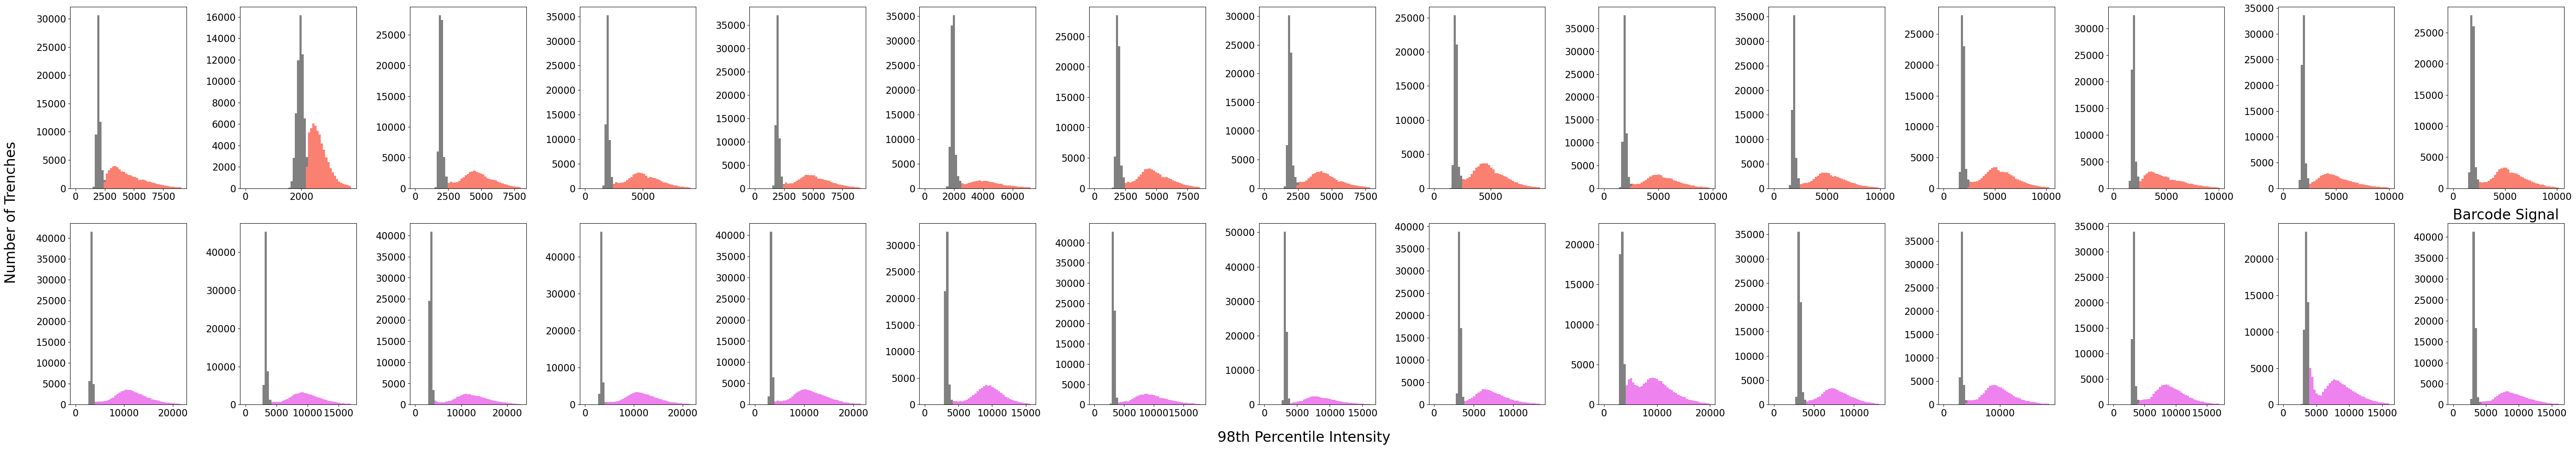

In [45]:
fish_test.export_bit_thresholds(figsize = (60,10))

In [ ]:
fish_test.output_barcode_df(
    dask_controller,
    headpath+"/barcode_output_df_fiducials_hamming-2_rmBits-1_expanded.hdf5",
)

Getting Barcode df...


/home/lag36/paulssonlab/paulssonlab/src/paulssonlab/deaton/trenchripper/trenchripper/marlin.py:728: UserWarning: `meta` is not specified, inferred from partial data. Please provide `meta` if the result is unexpected.
  Before: .apply(func)
  After:  .apply(func, meta={'x': 'f8', 'y': 'f8'}) for dataframe result
  or:     .apply(func, meta=('x', 'f8'))            for series result
  barcodes = trench_group.apply(lambda x: list(itertools.chain.from_iterable([x[channel].tolist()\
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 446.51 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


Getting Nanopore df...
Merging...


/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/array/routines.py:443: PerformanceWarning: Increasing number of chunks by factor of 42
  out = blockwise(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask/array/routines.py:443: PerformanceWarning: Increasing number of chunks by factor of 42
  out = blockwise(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 30.22 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/client.py:3163: UserWarning: Sending large graph of size 30.22 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/zarr/creation.py:295: UserWarning: ignoring keyword argument 'inline_array'
  warn(

In [48]:
print(1)

1


In [28]:
dask_controller.shutdown()

Done.


2025-03-25 12:20:23,560 - distributed.deploy.adaptive_core - INFO - Adaptive stop


In [ ]:
print('a')

In [ ]:
dask_controller.shutdown()

In [29]:
import pandas as pd

In [122]:
# df = pd.read_hdf(
#     "/home/lag36/scratch/lag36/2023-10-31_lLAG2_AF555-AllCycles/Barcodes/barcode_output_df.hdf5"
# )

df = pd.read_hdf(
    "/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/barcode_output_df.hdf5"
)

In [30]:
import pandas as pd

def read_barcode_output_hdf5(filename: str) -> tuple[pd.DataFrame, dict]:
    '''
    Reads the barcode output df (the one after the FISH barcode calling is done),
    and its metadata
    '''
    df_bar_fish = pd.read_hdf(filename) #read in the barcode fish data
    with pd.HDFStore(filename,'r') as store:
        df_bar_fish_metadata = store.get_storer('barcodes').attrs.metadata

    return df_bar_fish, df_bar_fish_metadata

def print_stats(df_bar_fish: pd.DataFrame,
                df_bar_fish_metadata: pd.DataFrame) -> None:
    '''
    Prints some stats from the barcode output df metadata
    '''
    print("Total trenches:           ", df_bar_fish_metadata['Total Trenches'])
    print("Total Trenches With Cells: ", df_bar_fish_metadata['Total Trenches With Cells'])
    print("Removed Bits:             ", df_bar_fish_metadata['Removed Bits'])
    print("Hamming Threshold':      ", df_bar_fish_metadata['Hamming Threshold'])
    print("Called:                   ", len(df_bar_fish))
    print("Called percentage:        ", len(df_bar_fish)/df_bar_fish_metadata['Total Trenches With Cells'])

In [50]:
# prefix = '/home/lag36/scratch/lag36/Ecoli//2023-01-02_lDE20_Run_8/Barcodes/'
prefix = '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/'
filename = prefix + '/barcode_output_df_fiducials_hamming-2_rmBits-None_expanded.hdf5'
df_bar_fish, df_bar_fish_metadata = read_barcode_output_hdf5(filename)
print_stats(df_bar_fish, df_bar_fish_metadata)

Total trenches:            1075006
Total Trenches With Cells:  630987
Removed Bits:              []
Hamming Threshold':       2
Called:                    522638
Called percentage:         0.8282864781683299


In [49]:
# prefix = '/home/lag36/scratch/lag36/Ecoli//2023-01-02_lDE20_Run_8/Barcodes/'
prefix = '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/'
filename = prefix + '/barcode_output_df_fiducials_hamming-0_rmBits-1_expanded.hdf5'
df_bar_fish, df_bar_fish_metadata = read_barcode_output_hdf5(filename)
print_stats(df_bar_fish, df_bar_fish_metadata)

Total trenches:            1075006
Total Trenches With Cells:  619919
Removed Bits:              [1]
Hamming Threshold':       0
Called:                    364031
Called percentage:         0.5872234921013875


In [34]:
# prefix = '/home/lag36/scratch/lag36/Ecoli//2023-01-02_lDE20_Run_8/Barcodes/'
prefix = '/home/lag36/scratch/lag36/2024-08-16_lLAG8_Run-1/Barcodes/'
filename = prefix + '/barcode_output_df.hdf5'
df_bar_fish_2, df_bar_fish_metadata_2 = read_barcode_output_hdf5(filename)
print_stats(df_bar_fish_2, df_bar_fish_metadata_2)

Total trenches:            1075006
Total Trenches With Cells:  612218
Removed Bits:              [1]
Hamming Threshold':       0
Called:                    254438
Called percentage:         0.41560032537429475


In [32]:
df_bar_fish

,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
0,299,"[5255.380000000001, 0.0, 4729.460000000001, 21...",101000000000111010011011000110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,138.0,4,...,BSU_17890,276.0,tkt,GTGTTTTGCTGCCACACTGG,CCAGTGGGGCAGCAAAACAC,essential,0.506780,1050.0,100100100011001110000101001010,219788
1,477,"[2328.2800000000007, 0.0, 5066.82, 5482.82, 53...",001110110100101000011000011110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,219.0,3,...,BSU_22350,48.0,dnaD,CGTGAGCAGAATATTGGGGA,TCCCCAATCTTCTGCTCACG,essential,0.688151,1091.0,000000110010101111110011010010,100814
2,704,"[2115.0, 0.0, 3853.5600000000013, 4904.1200000...",001100001001110000101100011110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,560M2D529M,NaN,287.0,3,...,NaN,NaN,NaN,CGTTGTGCTACTCTTACGAA,TTCGTAAGAGTAGCACAACG,control,NaN,2566.0,000001110111000101001011100010,106398
3,1482,"[2192.0, 0.0, 7078.000000000016, 8083.30000000...",001111011110011000011110100111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,958M1D132M,NaN,4395.0,2,...,BSU_01770,296.0,glmM,CTGCACTGGGTTATGACAAG,CTTCTCATAACCCAGTGCAG,essential,0.437240,413.0,000010110001111110011101110111,14817
4,1776,"[2290.82, 0.0, 4642.460000000001, 4827.8800000...",001100010010001110101010111011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,2156.0,2,...,NaN,NaN,NaN,TGTGATGCATGGGGCTCTAG,CTAGAGCCCCATGCATCACA,control,NaN,2748.0,001110110100000111010110000111,90019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364026,1072541,"[3598.5600000000013, 0.0, 5515.500000000004, 1...",101011101110100110110110011111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,379M1I712M,NaN,337.0,3,...,BSU_29750,1024.0,aroA,TTCAGCCATTTTTCGAATTT,GAATTCGAAAAATGGCTGAA,auxotroph,0.261962,2297.0,101110100110111001101111110011,400089
364027,1073312,"[3336.6400000000003, 0.0, 1876.8200000000002, ...",100010111011001110011001110111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,488M1D602M,NaN,166.0,3,...,NaN,NaN,NaN,TCAATCGCAAGTCTGGGGGG,CCCCCCAGACTTGCGATTGA,control,NaN,2697.0,101111000000101111110001101111,402524
364028,1073454,"[1814.0, 0.0, 1754.6400000000003, 3868.7600000...",000100101001110101110100001011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1040M1D50M,NaN,12534.0,3,...,BSU_01190,256.0,rplB,GCGATGTTAGCTGAACGGTG,AACCGTTCAGCTAACATCGC,essential,0.303274,251.0,001001011111001000101010100011,150418
364029,1073851,"[1898.4600000000005, 0.0, 1875.6400000000003, ...",000101010010000111010011100101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,1993.0,3,...,BSU_01370,0.0,adk,CCATTCAGACTAAGTTCATT,AATGAACTTAGTCTTAATGG,essential,0.780575,362.0,001110011000011000010101001101,183838


In [ ]:
df['Category'].value_counts()

In [ ]:
len(df)

In [ ]:
df_single = pd.read_csv('./df_single.csv')

In [ ]:
# import dask.dataframe as dd
# df_meta = dd.read_parquet("/home/lag36/scratch/lag36/2024-02-05_lLAG2_Run2_All-15-Cycles-AF555/Barcodes/kymograph/metadata",calculate_divisions=True)
# df_single = df_meta.groupby('trenchid').first().compute()
# df_single
# df_single.to_csv('./df_single.csv')

In [ ]:
dask_controller.shutdown()

In [ ]:
# Count the frequency of unique barcode ids
df["barcodeid"].value_counts().hist(bins=100, figsize=(3, 3))

In [ ]:
dask_controller.shutdown()

In [ ]:
print("dun")

In [ ]:
df_single

In [ ]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

channels = ["BF", "RFP", "Cy5"]
trench_index = 100 # BAD: 1 (k30), GOOD: k30-20
with h5py.File(
    "/home/lag36/scratch/lag36/2024-02-05_lLAG2_Run2_All-15-Cycles-AF555/Barcodes/kymograph/kymograph_2.hdf5",
    "r",
) as infile:
    indices = list(range(0, 15, 1))
    for ch in channels:
        img = infile[ch][trench_index][indices[0]]
        for ind in indices[1:]:
            img_ind = infile[ch][trench_index][ind]
            img = np.concatenate((img, img_ind), axis=1)
        plt.figure(figsize=(4, 8))
        plt.imshow(img, cmap="gray", aspect=1)
        plt.show()
        plt.close()   



In [ ]:
# Select columns trenchid, fov, row, trench, lane orientation, File Index, and File Trench Index from df_single
df_single = df_single[["trenchid", "fov", "row", "trench", "lane orientation", "File Index", "File Trench Index"]]

In [ ]:
# Merge df_single with df using the trenchid column
df_merged = df_single.merge(df, on="trenchid")

In [ ]:
df_merged[df_merged['row']== 9]

In [ ]:
# TODO Make a viewer for the barcode assignments



In [ ]:
dask_controller.shutdown()